# Lecture 1: Cass-Koopmans Competitive Equilibrium — solved with Newton's method

**Lecture 1 of 9** · [Series index](README.md)

*Adapted from [Cass-Koopmans Competitive Equilibrium](https://python.quantecon.org/cass_koopmans_2.html) by Thomas J. Sargent and John Stachurski (QuantEcon), licensed under [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/). This version replaces the shooting/bisection algorithm with a stacked-system Newton solver in JAX, and is shared under the same licence. The Newton solver is adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html), also licensed under CC BY-SA 4.0.*

## Overview

This lecture continues the analysis of the optimal capital accumulation model studied by Tjalling Koopmans (1965) and David Cass (1965), begun in [Cass-Koopmans Planning Model](https://python.quantecon.org/cass_koopmans_1.html).

The theme is a general connection between a **planned economy** and an economy organised through **competitive markets**.

The planning lecture used

- a Lagrangian formulation of the planning problem that leads to a system of difference equations,
- a **shooting algorithm** for solving those difference equations subject to initial and terminal conditions, and
- a **turnpike** property of optimal paths in long-but-finite-horizon economies.

This lecture adds

- Hicks-Arrow prices, named after John R. Hicks and Kenneth Arrow,
- a link between Lagrange multipliers in the planning problem and Hicks-Arrow prices,
- the **Big $K$, little $k$** trick that is widely used in macroeconomic dynamics,
- a non-stochastic theory of the **term structure of interest rates**, and
- the close connection between two ways of organising an economy: **central planning**, where a planner commands the allocation of resources, and **competitive markets**, where prices lead self-interested consumers and firms to choose the socially optimal allocation as an unintended consequence.

The lecture has two parts. **Part I** follows the original lecture: solve the planning problem, use its allocation to guess equilibrium prices, and verify the guess. **Part II** solves the market economy directly from the agents' first-order conditions and market clearing, with no planner, and shows that it lands on the same allocation and prices.

### What is different about the computation

The original lecture solves the planning problem by *shooting*: guess $c_0$, iterate the Euler equation and resource constraint forward, and bisect on $c_0$ until the terminal condition on capital holds.

Here we instead treat the whole transition path as **one square system of nonlinear equations** — every Euler equation and every resource constraint for $t = 0, \ldots, T$ at once — and solve it with a multivariate Newton method. The Jacobian comes from automatic differentiation in JAX.

This is the same approach used to solve large computable general equilibrium (CGE) models. It has some practical advantages over shooting:

- it does not suffer from the explosive forward dynamics that make shooting numerically fragile for long horizons,
- it scales naturally to models with many state variables, where bisecting on a single initial condition is no longer possible, and
- it lets us solve the *decentralised* economy directly — stacking household and firm first-order conditions together with market clearing — which we do in Part II of this lecture.

In [1]:
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from collections import namedtuple

jax.config.update("jax_enable_x64", True)

I0000 00:00:1792974792.320150  280072 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792974792.330456  280072 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792974792.334364  280072 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792974792.380833  280072 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Review of the Cass-Koopmans model

The physical setting is identical to the one in [Cass-Koopmans Planning Model](https://python.quantecon.org/cass_koopmans_1.html).

Time is discrete, $t = 0, 1, \ldots, T$.

Output of a single good can be consumed or invested in physical capital. Capital is durable but depreciates at a constant rate each period.

Let $C_t$ be consumption at time $t$ and $K_t$ the stock of physical capital at time $t$. Let $\vec{C} = \{C_0, \ldots, C_T\}$ and $\vec{K} = \{K_0, \ldots, K_{T+1}\}$.

A representative household is endowed with one unit of labour at each $t$, which it supplies inelastically, so $N_t = 1$ for all $t \in \{0, 1, \ldots, T\}$.

The household ranks consumption plans by

$$
U(\vec{C}) = \sum_{t=0}^{T} \beta^t \frac{C_t^{1-\gamma}}{1-\gamma}
$$

where $\beta \in (0,1)$ is a discount factor and $\gamma > 0$ governs the curvature of one-period utility.

We assume $K_0 > 0$. The production function is

$$
F(K_t, N_t) = A K_t^{\alpha} N_t^{1-\alpha}
$$

with $0 < \alpha < 1$ and $A > 0$. Write $f(K) \equiv F(K, 1)$.

A feasible allocation $\vec{C}, \vec{K}$ satisfies

$$
C_t + K_{t+1} \leq F(K_t, N_t) + (1-\delta) K_t \quad \text{for all } t \in \{0, 1, \ldots, T\}
$$

where $\delta \in (0,1)$ is the depreciation rate.

### Planning problem

In the planning lecture a planner chooses $\{\vec{C}, \vec{K}\}$ to maximise $U(\vec C)$ subject to feasibility. With multiplier $\mu_t$ on the time-$t$ resource constraint, the first-order conditions are

$$
\begin{aligned}
u'(C_t) &= \mu_t \\
\mu_t &= \beta \mu_{t+1} \left[ f'(K_{t+1}) + 1 - \delta \right] \\
C_t + K_{t+1} &= f(K_t) + (1-\delta) K_t
\end{aligned}
$$

together with the initial condition $K_0$ and a terminal condition on $K_{T+1}$.

The allocation that solves the planning problem reappears in a competitive equilibrium, as we shall see.

## Competitive equilibrium

We now study a decentralised version of the economy with the same technology and preferences, but no planner.

Instead there are (unit masses of) price-taking consumers and firms, and market prices reconcile the separate decisions of a representative consumer and a representative firm.

- At each $t$ the household receives wages and capital rentals from the firm; these are its **income** at $t$.
- The household decides how to divide income between consumption and saving.
- It can save by acquiring physical capital (which trades one-for-one with time-$t$ consumption) or by acquiring claims on consumption at other dates.
- The household owns capital and labour and rents both to the firm.
- A profit-maximising representative firm operates the technology, rents labour and capital from the household each period, and sells output back to it.
- Both the household and the firm are **price takers**: each believes its choices do not affect prices.

## Market structure

The household owns both factors of production and rents them to the firm each period.

There is a **single** grand competitive market in which the household trades date-$0$ goods for goods at every other date $t = 1, 2, \ldots, T$.

### Prices

There are sequences $\{w_t, \eta_t\}_{t=0}^T = \{\vec{w}, \vec{\eta}\}$ where

- $w_t$ is the wage (rental rate for labour) at $t$, and
- $\eta_t$ is the rental rate for capital at $t$.

There is also a vector of intertemporal prices $\{q_t^0\}_{t=0}^T$, where $q_t^0$ is the price at time $0$ of one unit of the good delivered at $t$. These are **Hicks-Arrow prices**.

Because only relative prices matter, we can rescale all $q_t^0$ by any $\lambda > 0$. A natural choice is to measure $q_t^0$ in

$$
\frac{\text{number of time-0 goods}}{\text{number of time-}t\text{ goods}}
$$

so that time-0 consumption is the **numeraire** and $q_0^0 = 1$.

It will also be convenient to define the **net** return on capital

$$
r_t \equiv \eta_t - \delta
$$

which is what the household earns per unit of capital after replacing depreciation.

## Firm problem

At $t$ the firm hires labour $\tilde n_t$ and capital $\tilde k_t$. Its profits are

$$
F(\tilde k_t, \tilde n_t) - w_t \tilde n_t - \eta_t \tilde k_t
$$

with $F(\tilde k_t, \tilde n_t) = A \tilde k_t^\alpha \tilde n_t^{1-\alpha}$.

### Zero-profit conditions

The zero-profit conditions are

$$
F_k(\tilde k_t, \tilde n_t) = \eta_t, \qquad F_n(\tilde k_t, \tilde n_t) = w_t
$$

They follow from a no-arbitrage argument. Because $F$ has constant returns to scale, Euler's theorem for homogeneous functions gives

$$
F(\tilde k_t, \tilde n_t) = \frac{\partial F}{\partial \tilde k_t}\tilde k_t + \frac{\partial F}{\partial \tilde n_t}\tilde n_t
$$

so profits can be written as

$$
\left(\frac{\partial F}{\partial \tilde k_t} - \eta_t\right)\tilde k_t + \left(\frac{\partial F}{\partial \tilde n_t} - w_t\right)\tilde n_t
$$

The marginal products are homogeneous of degree zero, so they depend only on the ratio $\tilde k_t / \tilde n_t$, not on scale. If $\partial F / \partial \tilde k_t > \eta_t$ the firm earns positive profit on every extra unit of capital and would want infinite capital, which is infeasible; if $\partial F / \partial \tilde k_t < \eta_t$ it would want zero capital. Equilibrium prices must rule out both, and the same argument applies to labour.

## Household problem

At $t$ the household rents $1$ unit of labour and $k_t$ units of capital to the firm, earning $w_t + \eta_t k_t$.

It spends on consumption $c_t$ and net investment $k_{t+1} - (1-\delta)k_t$.

In any period the household may spend more than its income, provided it spends less in other periods. Its net excess demand for time-$t$ goods is

$$
e_t \equiv \left(c_t + k_{t+1} - (1-\delta)k_t\right) - \left(w_t + \eta_t k_t\right)
$$

Let $\vec{c} = \{c_0, \ldots, c_T\}$ and $\vec{k} = \{k_1, \ldots, k_{T+1}\}$, with $k_0$ given. The household faces a **single** present-value budget constraint

$$
\sum_{t=0}^T q_t^0 e_t \leq 0
$$

and solves

$$
\max_{\vec{c}, \vec{k}} \sum_{t=0}^T \beta^t u(c_t)
\quad \text{subject to} \quad
\sum_{t=0}^T q_t^0 \left(c_t + k_{t+1} - (1-\delta)k_t - w_t - \eta_t k_t\right) \leq 0
$$

Units: $w_t$ is time-$t$ goods per unit of time-$t$ labour; $\eta_t$ is time-$t$ goods per unit of time-$t$ capital; $q_t^0$ is numeraire per unit of the time-$t$ good.

### Definitions

- A **price system** is a sequence $\{q_t^0, \eta_t, w_t\}_{t=0}^T = \{\vec q, \vec\eta, \vec w\}$.
- An **allocation** is a sequence $\{c_t, k_{t+1}, n_t = 1\}_{t=0}^T = \{\vec c, \vec k, \vec n\}$.
- A **competitive equilibrium** is a price system and an allocation such that, given the prices, the allocation solves both the household's problem and the firm's problem.

We imagine all trades occur once and for all just before time $0$.

## Computing a competitive equilibrium

We use **guess and verify**: guess equilibrium price sequences, then verify that at those prices the household and the firm choose the same allocation.

### Guess for the price system

We construct the guess from the allocation $\{\vec C, \vec K, \vec N\}$ that solves the planning problem. That allocation plays the role of **Big $K$** in the Big $K$, little $k$ trick:

- obtain first-order conditions for the firm and the household,
- replace the agents' own choice variables with the planning quantities $\vec C, \vec K$,
- solve for $\{\vec q, \vec\eta, \vec w\}$ as functions of $\vec C, \vec K$, and
- verify that at these prices $c_t = C_t$, $k_t = \tilde k_t = K_t$ and $\tilde n_t = 1$.

The guess is, for $t = 0, \ldots, T$,

$$
q_t^0 = \beta^t \frac{u'(C_t)}{u'(C_0)}, \qquad
w_t = f(K_t) - K_t f'(K_t), \qquad
\eta_t = f'(K_t)
$$

(Here we have already normalised so that $q_0^0 = 1$; the original lecture's $q_t^0 = \beta^t u'(C_t)$ differs only by the constant $u'(C_0)$.)

If the guess is right then the household's and firm's choices coincide with the planning allocation:

$$
k_t^* = \tilde k_t^* = K_t, \qquad \tilde n_t^* = 1, \qquad c_t^* = C_t
$$

### Household's Lagrangian

$$
\mathcal{L}(\vec c, \vec k, \lambda) = \sum_{t=0}^T \beta^t u(c_t) + \lambda \sum_{t=0}^T q_t^0 \left( (1-\delta)k_t + w_t + \eta_t k_t - c_t - k_{t+1} \right)
$$

First-order conditions are

$$
\begin{aligned}
c_t:&\quad \beta^t u'(c_t) - \lambda q_t^0 = 0, & t &= 0, \ldots, T \\
k_t:&\quad -\lambda q_t^0 \left[(1-\delta) + \eta_t\right] + \lambda q_{t-1}^0 = 0, & t &= 1, \ldots, T+1 \\
\lambda:&\quad \sum_{t=0}^T q_t^0 \left(c_t + k_{t+1} - (1-\delta)k_t - w_t - \eta_t k_t\right) \leq 0
\end{aligned}
$$

plus a complementary-slackness condition on $k_{T+1}$.

Substituting the guessed prices:

- The $c_t$ condition becomes $u'(c_t) = \frac{\lambda}{u'(C_0)} u'(C_t)$. With multiplier $\lambda = u'(C_0)$ it is satisfied by $c_t = C_t$, and $u'(C_t) = \mu_t$ is the planner's first condition.
- The $k_t$ condition becomes $\beta \mu_t [1 - \delta + f'(K_t)] = \mu_{t-1}$, the planner's Euler equation.
- In the budget constraint, $w_t + \eta_t K_t = f(K_t)$, so it collapses to $\sum_t \beta^t \mu_t \left(C_t + K_{t+1} - (1-\delta)K_t - f(K_t)\right) \leq 0$. Since $\beta^t\mu_t > 0$ and each term is non-positive by feasibility, every term must be zero: the planner's resource constraint.

So at the guessed prices, the planning allocation solves the household's problem.

### Representative firm's problem

Plugging $\tilde k_t = K_t$, $\tilde n_t = 1$ into the zero-profit conditions gives $f'(K_t) = \eta_t$ and $f(K_t) - K_t f'(K_t) = w_t$ — exactly the guessed prices. So the planning allocation also solves the firm's problem, and household and firm choices coincide.

Because budget sets depend only on relative prices, $\{q_t^0\}$ is determined only up to a positive constant; our normalisation fixes $q_0^0 = 1$.

## Solving the planning problem with Newton's method

### The model in code

Parameters live in a `namedtuple`. Following the original lecture we set $k_0 = k_{ss}/3$.

The terminal condition $k_{T+1} = k_{\text{ter}}$ is a parameter. It defaults to the steady state $k_{ss}$; setting it to $0$ reproduces the original lecture, where the planner runs capital down to zero at the end of the horizon.

In [2]:
Settings = namedtuple('Settings', ['beta', 'gamma', 'delta', 'alpha', 'A', 'T', 'k0', 'k_ter'])


def k_steady(beta, delta, alpha, A):
    return ((1 / beta - (1 - delta)) / (alpha * A)) ** (1 / (alpha - 1))


def get_settings(beta=0.95, gamma=2.0, delta=0.02, alpha=0.33, A=1.0,
                 T=50, k0_frac=1/3, k_ter=None):
    k_ss = k_steady(beta, delta, alpha, A)
    k_ter = k_ss if k_ter is None else k_ter
    return Settings(beta, gamma, delta, alpha, A, T, k0_frac * k_ss, k_ter)


# ----- primitives -----
def u_prime(c, s):
    return c ** (-s.gamma)


def f_prod(k, s):
    return s.A * k ** s.alpha


def f_prime(k, s):
    return s.alpha * s.A * k ** (s.alpha - 1)


def steady_state(s):
    k_ss = k_steady(s.beta, s.delta, s.alpha, s.A)
    c_ss = f_prod(k_ss, s) - s.delta * k_ss
    return k_ss, c_ss

### The stacked system

Given $k_0$ and $k_{T+1} = k_{\text{ter}}$, the optimal path solves

$$
\begin{aligned}
\text{Resource:}\quad & k_{t+1} - f(k_t) - (1-\delta)k_t + c_t = 0, & t &= 0, \ldots, T \\
\text{Euler:}\quad & \log u'(c_t) - \log\!\left(\beta\, u'(c_{t+1}) \left[f'(k_{t+1}) + 1 - \delta\right]\right) = 0, & t &= 0, \ldots, T-1
\end{aligned}
$$

That is $(T+1) + T = 2T+1$ equations in the $2T+1$ unknowns $(c_0, \ldots, c_T, k_1, \ldots, k_T)$.

Two implementation choices matter:

- **Unknowns in logs.** We solve for $x = \log(c_0, \ldots, c_T, k_1, \ldots, k_T)$. This keeps every iterate strictly positive, so $u'$ and $f'$ are always defined, and puts consumption and capital — which differ in scale by an order of magnitude — on a comparable footing.
- **Euler equation in logs.** Marginal utility $c^{-\gamma}$ varies enormously when $\gamma$ is large; taking logs makes the residual close to linear in $\log c$, which helps Newton converge.

Note that $k_{T+1}$ is fixed, so it enters only the last resource constraint. That is why a terminal value of exactly zero is fine even though the unknowns are in logs.

In [3]:
def unpack(x, s):
    # x = log(c_0..c_T, k_1..k_T)  ->  c (T+1,), k (T+2,) incl. k_0 and k_{T+1}
    c = jnp.exp(x[:s.T + 1])
    k = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[s.T + 1:]), jnp.array([s.k_ter])])
    return c, k


def transition_solve(x, s, solving=1):
    c, k = unpack(x, s)
    # resource constraint, t = 0..T
    resource = k[1:] - (f_prod(k[:-1], s) + (1 - s.delta) * k[:-1] - c)
    # Euler equation in logs, t = 0..T-1
    euler = (jnp.log(u_prime(c[:-1], s))
             - jnp.log(s.beta * u_prime(c[1:], s) * (f_prime(k[1:-1], s) + 1 - s.delta)))
    errors = jnp.concatenate([resource, euler])
    if solving:
        return errors
    return errors, c, k

### Newton's method

Newton's method updates a guess $x^{(n)}$ by solving the linearised system

$$
x^{(n+1)} = x^{(n)} - a\, J(x^{(n)})^{-1} G(x^{(n)})
$$

where $G$ stacks the residuals above and $J$ is its Jacobian. JAX computes $J$ exactly by automatic differentiation, and `jax.jit` compiles the update step.

The step size $a$ lets us **damp** the iteration. Far from the solution a full Newton step can overshoot into regions where the model is badly behaved, so we take damped steps ($a = 0.3$) until the iterates settle, then switch to full steps ($a = 1$) to get quadratic convergence to machine precision — the same pattern commonly used for large CGE models.

The `newton` routine below is adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html), which uses JAX's automatic differentiation and `jax.jit` in the same way. We add the step-size argument `adj` for damping and an option to print the iterations.

In [4]:
def newton(f, x_0, tol=1e-5, max_iter=15, adj=1, verbose=True):
    # A multivariate Newton root-finding routine.
    x = x_0
    f_jac = jax.jacobian(f)

    @jax.jit
    def q(x, adj):
        # Updates the current guess.
        return x - adj * jnp.linalg.solve(f_jac(x), f(x))

    error = 1e10
    n = 0
    while error > tol:
        n += 1
        if n > max_iter:
            print('Max iteration reached without convergence')
            return x
        y = q(x, adj)
        error = jnp.linalg.norm(x - y)
        x = y
        if verbose:
            print(f'iteration {n}, error = {error}')
    return x

For the initial guess we put consumption at its steady-state value in every period and draw capital along a straight line from $k_0$ to $k_{T+1}$.

In [5]:
def steady_state_guess(s):
    k_ss, c_ss = steady_state(s)
    c = c_ss * np.ones(s.T + 1)
    k = np.linspace(s.k0, s.k_ter, s.T + 2)[1:-1]
    return np.log(np.hstack((c, k)))


def solve_planner(s, verbose=False):
    f = lambda x: transition_solve(x, s, 1)
    x0 = steady_state_guess(s)
    x1 = newton(f, x0, tol=1e-6, max_iter=500, adj=0.3, verbose=verbose)   # damped
    x = newton(f, x1, tol=1e-12, max_iter=100, adj=1, verbose=verbose)     # full Newton
    errors, c, k = transition_solve(x, s, 0)
    return np.asarray(c), np.asarray(k), float(jnp.max(jnp.abs(errors)))

Let's solve the benchmark economy with $T = 50$ and print the iterations of the final, full-step Newton phase. Notice how the error collapses once the iterates are close: the hallmark of quadratic convergence.

In [6]:
s = get_settings()
k_ss, c_ss = steady_state(s)
print(f'k_ss = {k_ss:.4f}, c_ss = {c_ss:.4f}, k_0 = {s.k0:.4f}')

f = lambda x: transition_solve(x, s, 1)
x1 = newton(f, steady_state_guess(s), tol=1e-6, max_iter=500, adj=0.3, verbose=False)
x = newton(f, x1, tol=1e-12, max_iter=100, adj=1)

errors, c, k = transition_solve(x, s, 0)
print(f'max |residual| = {float(jnp.max(jnp.abs(errors))):.2e}')

k_ss = 9.5758, c_ss = 1.9161, k_0 = 3.1919


ERROR:2026-10-26 11:33:15,188:jax._src.xla_bridge:473: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda13.initialize()
Traceback (most recent call last):
  File "/home/harveyt47/anaconda3/lib/python3.12/site-packages/jax_plugins/xla_cuda13/__init__.py", line 201, in _version_check
    version = get_version()
              ^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:34: operation cudaRuntimeGetVersion(&version) failed: Error loading CUDA libraries. GPU will not be used.

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/home/harveyt47/anaconda3/lib/python3.12/site-packages/jax/_src/xla_bridge.py", line 471, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/home/harveyt47/anaconda3/lib/python3.12/site-packages/jax_plugins/xla_cuda13/__init__.py", line 328, in initialize
    _check_cuda_versions(raise_on_first_error=True)
  File "/home/harveyt47/anaconda3/lib/python3.1

iteration 1, error = 1.8545469099698864e-06
iteration 2, error = 5.748066153591554e-13
max |residual| = 3.55e-15


iteration 1, error = 1.8545469103468563e-06
iteration 2, error = 5.740356085076231e-13


max |residual| = 5.33e-15


## Equilibrium prices

With the planning allocation in hand, the guessed price system is immediate.

In [7]:
def prices(c, k, s, t0=0):
    # Competitive equilibrium prices.  q is normalised so that q_{t0} = 1
    # (the time-t0 good is numeraire).
    T1 = len(c)
    t = np.arange(T1)
    q = s.beta ** (t - t0) * u_prime(c, s) / u_prime(c[t0], s)
    eta = f_prime(k[:T1], s)                                # rental rate on capital
    w = f_prod(k[:T1], s) - k[:T1] * f_prime(k[:T1], s)    # wage
    r = eta - s.delta                                       # net return on capital
    return q, eta, w, r

### Verifying the competitive equilibrium numerically

The algebra above shows that the planning allocation, at these prices, satisfies every household and firm optimality condition. Because we have the whole path as an array, we can also check this directly — compute each condition's residual and confirm it is zero to machine precision.

We check, at the guessed prices and planning allocation:

1. the household's $c_t$ condition $\beta^t u'(c_t) = \lambda q_t^0$ with $\lambda = u'(c_0)$,
2. the household's $k_t$ condition $q_{t-1}^0 = q_t^0 (1 - \delta + \eta_t)$ for $t = 1, \ldots, T$,
3. the household's present-value budget constraint,
4. the firm's zero-profit condition $f(k_t) - w_t - \eta_t k_t = 0$, and
5. goods-market clearing.

(The household's $k_{T+1}$ condition is replaced here by the fixed terminal condition, so we check the $k_t$ conditions only up to $T$.)

In [8]:
def check_equilibrium(c, k, s):
    q, eta, w, r = prices(c, k, s)
    T = len(c) - 1
    t = np.arange(T + 1)
    lam = u_prime(c[0], s)

    e = c + k[1:] - (1 - s.delta) * k[:-1] - (w + eta * k[:-1])   # net excess demand
    checks = {
        'household FOC for c_t':  np.max(np.abs(s.beta ** t * u_prime(c, s) - lam * q)),
        'household FOC for k_t':  np.max(np.abs(q[:-1] - q[1:] * (1 - s.delta + eta[1:]))),
        'PV budget constraint':   abs(np.sum(q * e)),
        'firm zero profit':       np.max(np.abs(f_prod(k[:-1], s) - w - eta * k[:-1])),
        'goods market clearing':  np.max(np.abs(c + k[1:] - (1 - s.delta) * k[:-1] - f_prod(k[:-1], s))),
    }
    for name, val in checks.items():
        print(f'{name:<25s} max |residual| = {val:.2e}')


c, k = np.asarray(c), np.asarray(k)
check_equilibrium(c, k, s)

household FOC for c_t     max |residual| = 5.55e-17
household FOC for k_t     max |residual| = 5.55e-16
PV budget constraint      max |residual| = 5.16e-16
firm zero profit          max |residual| = 1.11e-16
goods market clearing     max |residual| = 3.55e-15


Every condition holds to machine precision, confirming that the planning allocation and the guessed prices form a competitive equilibrium.

### Prices and quantities as the horizon varies

We now plot $q_t^0, w_t, \eta_t, c_t, k_t$ and the multiplier $\mu_t = u'(c_t)$ for several horizons $T$.

To match the original lecture we set the terminal condition $k_{T+1} = 0$, so the planner consumes the capital stock at the end of the horizon.

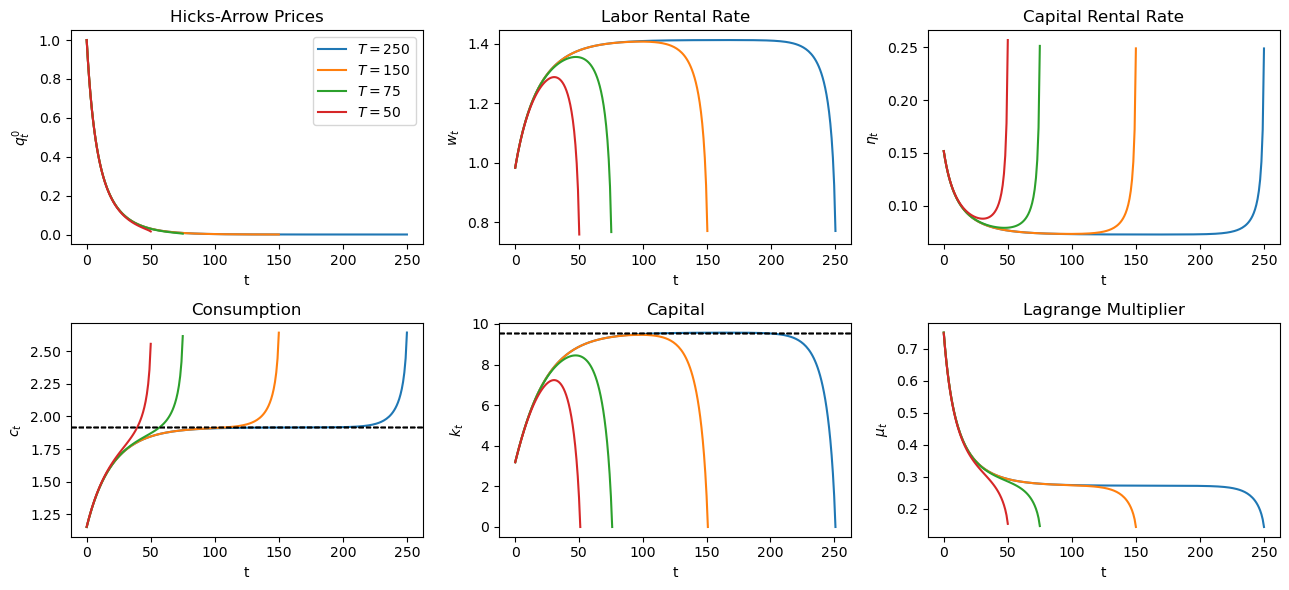

In [9]:
titles = ['Hicks-Arrow Prices', 'Labor Rental Rate', 'Capital Rental Rate',
          'Consumption', 'Capital', 'Lagrange Multiplier']
ylabels = ['$q_t^0$', '$w_t$', r'$\eta_t$', '$c_t$', '$k_t$', r'$\mu_t$']


def plot_paths(settings_list, labels=None):
    fig, axs = plt.subplots(2, 3, figsize=(13, 6))
    for j, s in enumerate(settings_list):
        c, k, res = solve_planner(s)
        assert res < 1e-10, f'not converged: {res}'
        q, eta, w, r = prices(c, k, s)
        mu = u_prime(c, s)
        paths = [q, w, eta, c, k, mu]
        k_ss, c_ss = steady_state(s)
        for i, ax in enumerate(axs.flatten()):
            lab = labels[j] if labels is not None else None
            ax.plot(paths[i], label=lab)
            ax.set(title=titles[i], ylabel=ylabels[i], xlabel='t')
            if titles[i] == 'Capital':
                ax.axhline(k_ss, lw=1, ls='--', c='k')
            if titles[i] == 'Consumption':
                ax.axhline(c_ss, lw=1, ls='--', c='k')
    if labels is not None:
        axs[0, 0].legend()
    plt.tight_layout()
    plt.show()


T_arr = [250, 150, 75, 50]
plot_paths([get_settings(T=T, k_ter=0.0) for T in T_arr],
           labels=[f'$T = {T}$' for T in T_arr])

The **turnpike** property is visible: for long horizons the economy approaches the steady state, stays near it for most of the horizon, and only leaves it near the end, when capital is run down. Prices mirror the quantities — the rental rate on capital $\eta_t$ falls as capital accumulates and spikes as capital is consumed at the end, while the wage moves the other way.

If instead we impose $k_{T+1} = k_{ss}$ (the default in `get_settings`), there is no end-of-horizon run-down, and the paths for different $T$ become almost indistinguishable:

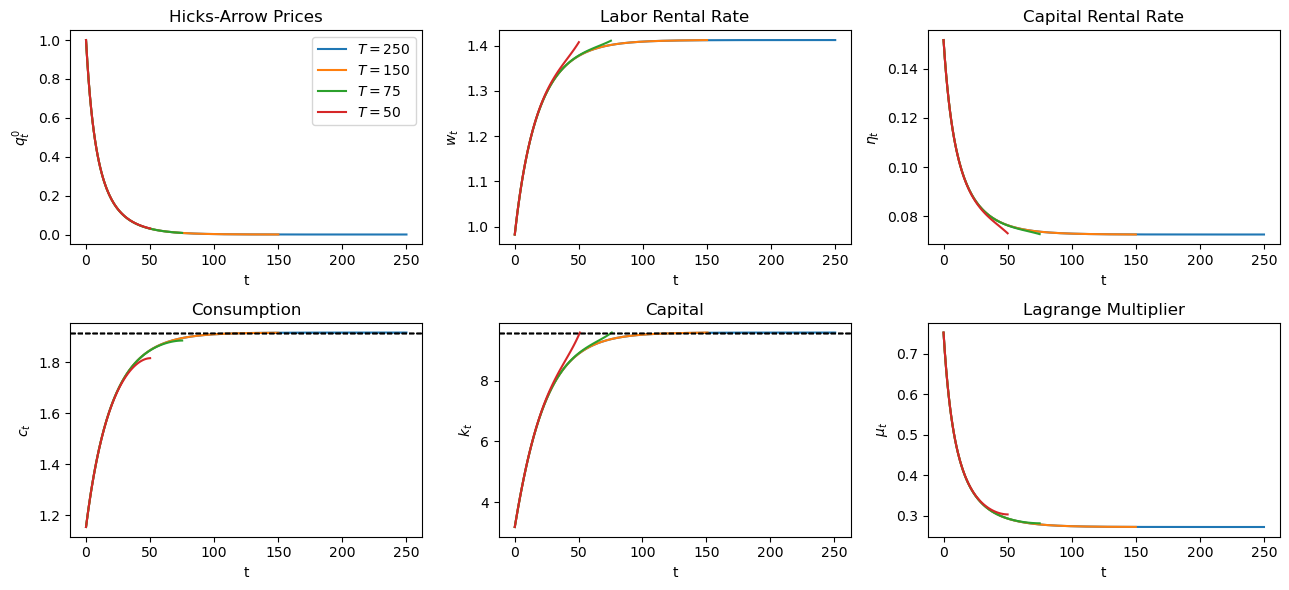

In [10]:
plot_paths([get_settings(T=T) for T in T_arr],
           labels=[f'$T = {T}$' for T in T_arr])

#### Varying curvature

Now hold $T = 150$ fixed (again with $k_{T+1} = 0$) and vary the curvature parameter $\gamma$, starting from $K_0$ below the steady state.

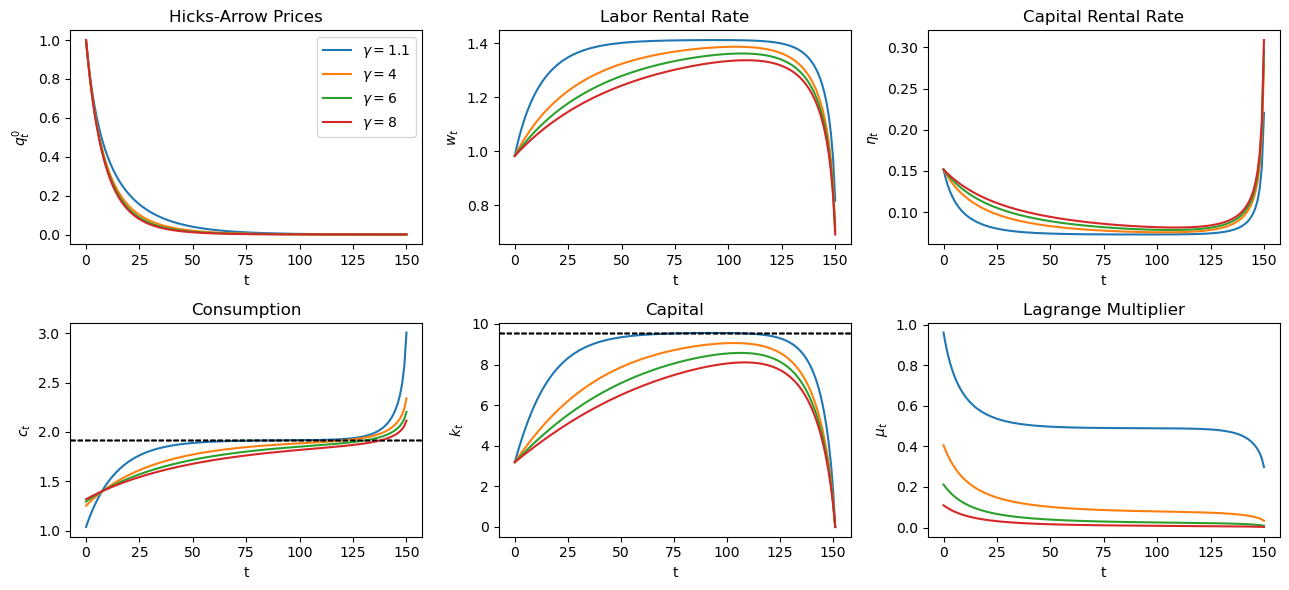

In [11]:
γ_arr = [1.1, 4, 6, 8]
plot_paths([get_settings(T=150, gamma=γ, k_ter=0.0) for γ in γ_arr],
           labels=[fr'$\gamma = {γ}$' for γ in γ_arr])

Raising $\gamma$ raises the household's desire to smooth consumption. Households with high $\gamma$ start with higher consumption and accumulate capital more slowly, so the economy converges to the steady state more slowly. Lower $\gamma$ means less concern for smoothing and faster convergence.

Large $\gamma$ is where the shooting algorithm tends to struggle, because small errors in $c_0$ are amplified sharply along the forward path; the stacked Newton system handles every case here without difficulty.

## Yield curves and Hicks-Arrow prices

We return to Hicks-Arrow prices and link them to **yields** on loans of different maturities. This gives a **yield curve**: yields on bonds of maturities $j = 1, 2, \ldots$ plotted against $j$.

The **yield to maturity** on a loan made at $t_0$ that matures at $t > t_0$ is

$$
r_{t_0, t} = -\frac{\log q_t^{t_0}}{t - t_0}
$$

where the Hicks-Arrow price system with base year $t_0 \leq t$ is

$$
q_t^{t_0} = \beta^{t - t_0} \frac{u'(c_t)}{u'(c_{t_0})} = \beta^{t - t_0} \frac{c_t^{-\gamma}}{c_{t_0}^{-\gamma}}
$$

Our `prices` function already takes a base year `t0`, so we only need a function for yields.

In [12]:
def yields(q, t0):
    # Yield to maturity r_{t0,t} for t = t0+1..T, given q normalised at t0
    q_fwd = q[t0:]
    return -np.log(q_fwd[1:]) / np.arange(1, len(q_fwd))


def plot_yield_curves(t0, T_arr, **kwargs):
    fig, axs = plt.subplots(1, 2, figsize=(10, 5))
    for T in T_arr:
        s = get_settings(T=T, **kwargs)
        c, k, _ = solve_planner(s)
        q, *_ = prices(c, k, s, t0=t0)
        r = yields(q, t0)

        axs[0].plot(range(t0, T + 1), q[t0:], label=f'$T = {T}$')
        axs[0].set(xlabel='t', ylabel=f'$q_t^{{{t0}}}$', title='Hicks-Arrow Prices')

        axs[1].plot(range(t0 + 1, T + 1), r, label=f'$T = {T}$')
        axs[1].set(xlabel='t', ylabel=f'$r_{{{t0},t}}$', title='Yields')
    axs[1].legend()
    plt.tight_layout()
    plt.show()

First take $t_0 = 0$ and plot for several horizons $T$, with $K_0$ below the steady state and (as in the original lecture) $k_{T+1} = 0$.

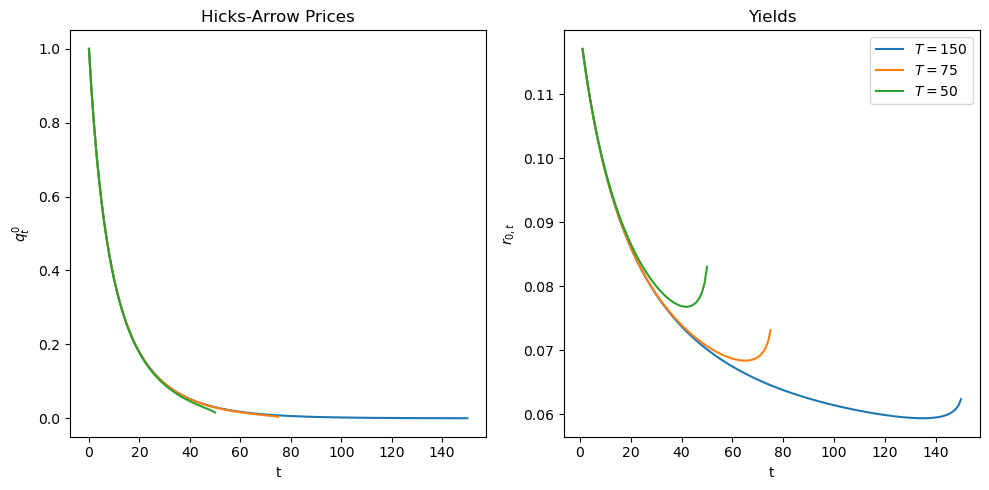

In [13]:
T_arr = [150, 75, 50]
plot_yield_curves(0, T_arr, k_ter=0.0)

Starting below the steady state, capital is scarce and its marginal product is high, so short-maturity yields are high. As the economy accumulates capital the return falls towards its steady-state level $1/\beta - 1$, so longer maturities carry lower yields: the yield curve slopes down. Near the end of the horizon the capital run-down lets consumption rise sharply, which lowers marginal utility and $q_t^0$ and pushes long yields back up.

Now set the base year to $t_0 = 20$:

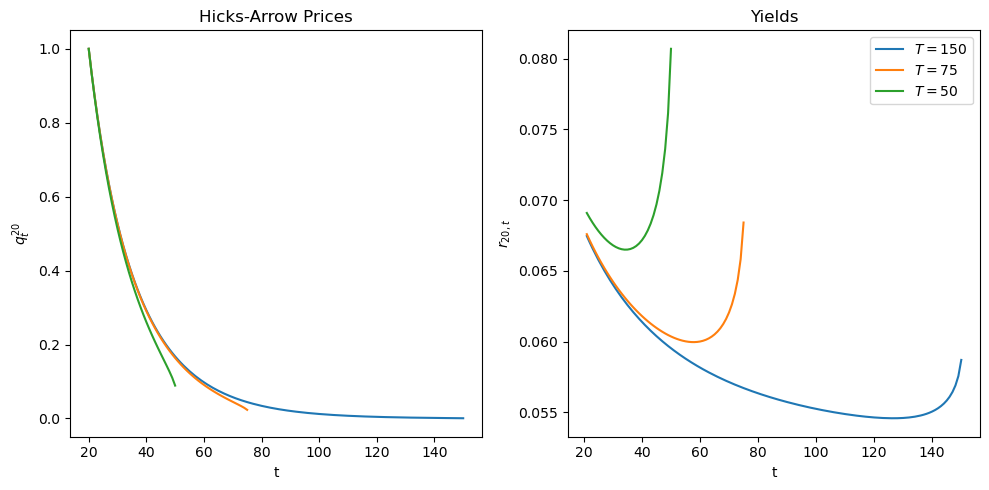

In [14]:
plot_yield_curves(20, T_arr, k_ter=0.0)

By $t = 20$ the economy is much closer to the steady state, so the initial portion of the yield curve is flatter and closer to $1/\beta - 1 \approx 5.3\%$; the only remaining shape comes from the residual transition and from the end-of-horizon run-down.

For comparison, with the terminal condition $k_{T+1} = k_{ss}$ the end-of-horizon distortion disappears and the long end of the yield curve converges to $1/\beta - 1$:

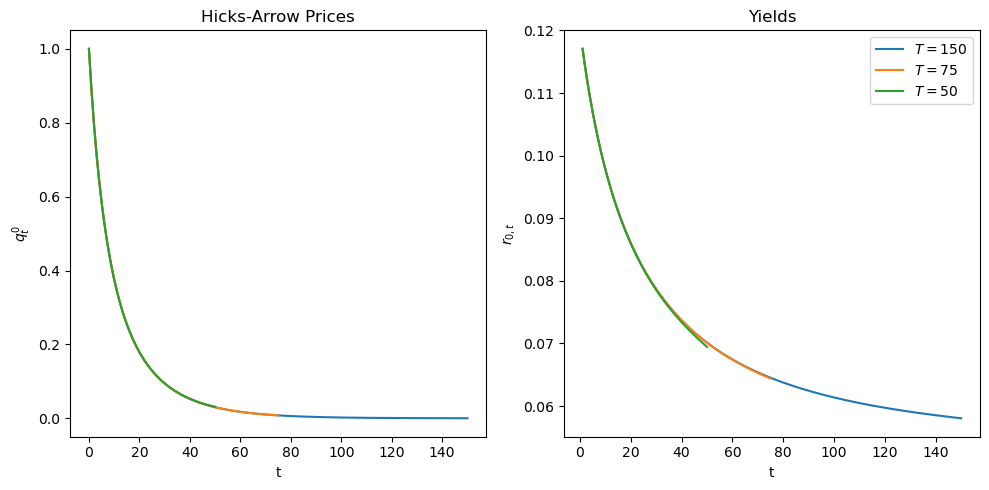

1/β - 1 = 0.0526


In [15]:
plot_yield_curves(0, T_arr)
print(f'1/β - 1 = {1 / 0.95 - 1:.4f}')

# Part II: The decentralised solution

Everything above followed the guess-and-verify strategy: solve the planning problem first, then read prices off the planner's allocation.

We now solve the market economy **directly**. Prices and quantities are both Newton unknowns, and the residuals are the agents' first-order conditions plus market clearing. The planner appears nowhere in the computation; it returns only at the end, as a check.

We do this for two market structures:

1. **Sequential markets.** Each period the household rents capital and labour to the firm, and saves by carrying capital into the next period. This is the structure most CGE models use.
2. **Date-0 markets.** The lecture's own setup: a single market at time $0$ in which the household trades claims to goods at every date, priced by Hicks-Arrow prices $q_t^0$.

Both turn out to deliver the planner's allocation.

## Sequential markets

### Agents

All agents are price takers.

**Household.** Owns the capital stock $k_t$ and supplies $N = 1$ unit of labour inelastically. Each period it faces a flow budget constraint rather than a single present-value constraint:

$$
\max_{\{c_t, k_{t+1}\}} \sum_{t=0}^T \beta^t u(c_t)
\quad \text{subject to} \quad
c_t + k_{t+1} = w_t + (r^k_t + 1 - \delta)\, k_t, \qquad t = 0, \ldots, T
$$

with $k_0$ given and $k_{T+1} = k_{\text{ter}}$. Here $r^k_t$ is the rental rate on capital — the lecture's $\eta_t$. Its first-order conditions give the Euler equation

$$
u'(c_t) = \beta\, u'(c_{t+1}) \left(r^k_{t+1} + 1 - \delta\right), \qquad t = 0, \ldots, T-1
$$

**Firm.** Each period rents capital $K_t$ and hires labour $N_t$ to maximise $A K_t^\alpha N_t^{1-\alpha} - r^k_t K_t - w_t N_t$. Its first-order conditions are

$$
r^k_t = \alpha A \left(\frac{K_t}{N_t}\right)^{\alpha - 1}, \qquad
w_t = (1 - \alpha) A \left(\frac{K_t}{N_t}\right)^{\alpha}
$$

Note that the firm chooses $K_t$ and $N_t$ — the **little $k$** of the firm — separately from the household's $k_t$. They are only brought into line by market clearing.

### Markets

$$
\begin{aligned}
\text{Capital:}\quad & K_t = k_t \\
\text{Labour:}\quad & N_t = 1 \\
\text{Goods:}\quad & Y_t = c_t + k_{t+1} - (1 - \delta) k_t
\end{aligned}
$$

The goods market is **redundant by Walras' law**. Because the technology has constant returns, the firm's first-order conditions imply $w_t N_t + r^k_t K_t = Y_t$: factor payments exhaust output. Substituting the capital and labour market-clearing conditions into the household's budget constraint then gives the goods-market condition. So we leave it out of the system and report it as a check, as one would in a CGE.

### The stacked system

The unknowns, all in logs, are $w_t, r^k_t, K_t, c_t$ for $t = 0, \ldots, T$ plus $k_1, \ldots, k_T$:

| Block | Equation | Periods | Count |
|---|---|---|---|
| Firm, capital | $\log r^k_t = \log\left(\alpha A (K_t/N_t)^{\alpha-1}\right)$ | $0..T$ | $T+1$ |
| Firm, labour | $\log w_t = \log\left((1-\alpha) A (K_t/N_t)^{\alpha}\right)$ | $0..T$ | $T+1$ |
| Household budget | $k_{t+1} + c_t = w_t + (r^k_t + 1 - \delta) k_t$ | $0..T$ | $T+1$ |
| Household Euler | $\log u'(c_t) = \log\left(\beta u'(c_{t+1})(r^k_{t+1} + 1 - \delta)\right)$ | $0..T-1$ | $T$ |
| Capital market | $K_t = k_t$ | $0..T$ | $T+1$ |

That is $5T + 4$ equations in $5T + 4$ unknowns.

### Recovering Hicks-Arrow prices

Sequential markets have no $q_t^0$ — only period-by-period rental rates. But no arbitrage links the two. A unit of the good at $t-1$ invested in capital returns $1 + r_t$ units at $t$, where $r_t = r^k_t - \delta$ is the net return. A claim to the time-$t$ good must therefore cost $1/(1 + r_t)$ time-$(t-1)$ goods, so

$$
q_t^0 = \prod_{s=1}^{t} \frac{1}{1 + r_s}, \qquad q_0^0 = 1
$$

This is just the household's $k_t$ first-order condition $q_{t-1}^0 = q_t^0 (1 - \delta + \eta_t)$ from the date-0 problem, iterated forward.

In [27]:
def dc_unpack(x, s):
    n = s.T + 1
    w, rk, K, c = (jnp.exp(x[i * n:(i + 1) * n]) for i in range(4))
    k = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[4 * n:]), jnp.array([s.k_ter])])  # k_0..k_{T+1}
    return w, rk, K, c, k


def market_clearing_solve(x, s, solving=1):
    w, rk, K, c, k = dc_unpack(x, s)

    # --- firm first-order conditions (t = 0..T) ---
    kl = K
    firm_k = jnp.log(rk) - jnp.log(s.alpha * s.A * kl ** (s.alpha - 1))
    firm_n = jnp.log(w) - jnp.log((1 - s.alpha) * s.A * kl ** s.alpha)

    # --- household: budget constraint (t = 0..T) and Euler equation (t = 0..T-1) ---
    budget = k[1:] + c - (w + (rk + 1 - s.delta) * k[:-1])
    euler = (jnp.log(u_prime(c[:-1], s))
             - jnp.log(s.beta * u_prime(c[1:], s) * (rk[1:] + 1 - s.delta)))

    # --- market clearing ---
    capital_mkt = K - k[:-1]          # K_t = k_t

    errors = jnp.concatenate([firm_k, firm_n, budget, euler, capital_mkt])
    if solving:
        return errors

    Y = s.A * K ** s.alpha * 1 ** (1 - s.alpha)
    goods_mkt = Y - (c + k[1:] - (1 - s.delta) * k[:-1])   # Walras check, should be ~0
    return errors, dict(w=w, rk=rk, K=K, c=c, k=k, Y=Y, goods_mkt=goods_mkt)

The initial guess puts prices and consumption at their steady-state values, labour at $1$, and capital on a straight line from $k_0$ to $k_{T+1}$ — the same kind of naive starting point as for the planner.

In [28]:
def dc_initial_guess(s):
    k_ss, c_ss = steady_state(s)
    n = s.T + 1
    rk_ss = 1 / s.beta - (1 - s.delta)
    w_ss = (1 - s.alpha) * s.A * k_ss ** s.alpha
    k_path = np.linspace(s.k0, s.k_ter, s.T + 2)
    return np.log(np.hstack((w_ss * np.ones(n), rk_ss * np.ones(n), k_path[:-1],
                             c_ss * np.ones(n), k_path[1:-1])))


def solve_decentralised(s, verbose=False):
    f = lambda x: market_clearing_solve(x, s, 1)
    x0 = dc_initial_guess(s)
    if verbose:
        print(f'initial max |residual| = {float(jnp.max(jnp.abs(f(x0)))):.2e}')

    x1 = newton(f, x0, tol=1e-6, max_iter=500, adj=0.3, verbose=False)   # damped
    x = newton(f, x1, tol=1e-12, max_iter=100, adj=1, verbose=verbose)   # full Newton

    errors, eq = market_clearing_solve(x, s, 0)
    eq = {key: np.asarray(v) for key, v in eq.items()}
    eq['residual'] = float(jnp.max(jnp.abs(errors)))

    # Hicks-Arrow prices implied by the sequential interest rates: q_t = prod_{s=1..t} 1/(1 + r_s)
    r = eq['rk'] - s.delta
    eq['q'] = np.concatenate([[1.0], np.cumprod(1 / (1 + r[1:]))])
    return eq

Let's solve the benchmark economy ($T = 150$, $k_{T+1} = k_{ss}$).

In [33]:
s = get_settings( T=150)
eq = solve_decentralised(s, verbose=True)

print(f'\n{5 * s.T + 4} unknowns')
print(f'max |FOC / market-clearing residual| = {eq["residual"]:.2e}')
print(f'max |goods market (Walras) residual|  = {np.max(np.abs(eq["goods_mkt"])):.2e}')

initial max |residual| = 7.36e-01
iteration 1, error = 2.2729515465040827e-06
iteration 2, error = 7.352650713503141e-14

754 unknowns
max |FOC / market-clearing residual| = 7.11e-15
max |goods market (Walras) residual|  = 6.22e-15


iteration 1, error = 2.0344064474838245e-06
iteration 2, error = 2.119124027321381e-13

305 unknowns
max |FOC / market-clearing residual| = 5.33e-15
max |goods market (Walras) residual|  = 4.44e-15


The goods market clears even though it is not in the system — Walras' law at work.

### Comparing with the planner

Now bring the planner back. If the first welfare theorem holds, the decentralised allocation should coincide with the planner's, and the decentralised prices should coincide with the prices we derived from the planner's allocation in Part I.

In [34]:
def compare_with_planner(s, eq, verbose=True):
    # Welfare-theorem check: decentralised equilibrium == planner's allocation and supporting prices
    c_p, k_p, _ = solve_planner(s)
    q_p, eta_p, w_p, _ = prices(c_p, k_p, s)
    diffs = {'c': np.max(np.abs(eq['c'] - c_p)),
             'k': np.max(np.abs(eq['k'] - k_p)),
             'q': np.max(np.abs(eq['q'] - q_p)),
             'w': np.max(np.abs(eq['w'] - w_p)),
             'rk (= eta)': np.max(np.abs(eq['rk'] - eta_p))}
    if verbose:
        print('--- decentralised vs planner ---')
        for name, d in diffs.items():
            print(f'max |{name} diff| = {d:.2e}')
    return max(diffs.values())


compare_with_planner(s, eq);

--- decentralised vs planner ---
max |c diff| = 1.55e-15
max |k diff| = 1.78e-14
max |q diff| = 3.89e-16
max |w diff| = 1.33e-15
max |rk (= eta) diff| = 8.33e-17


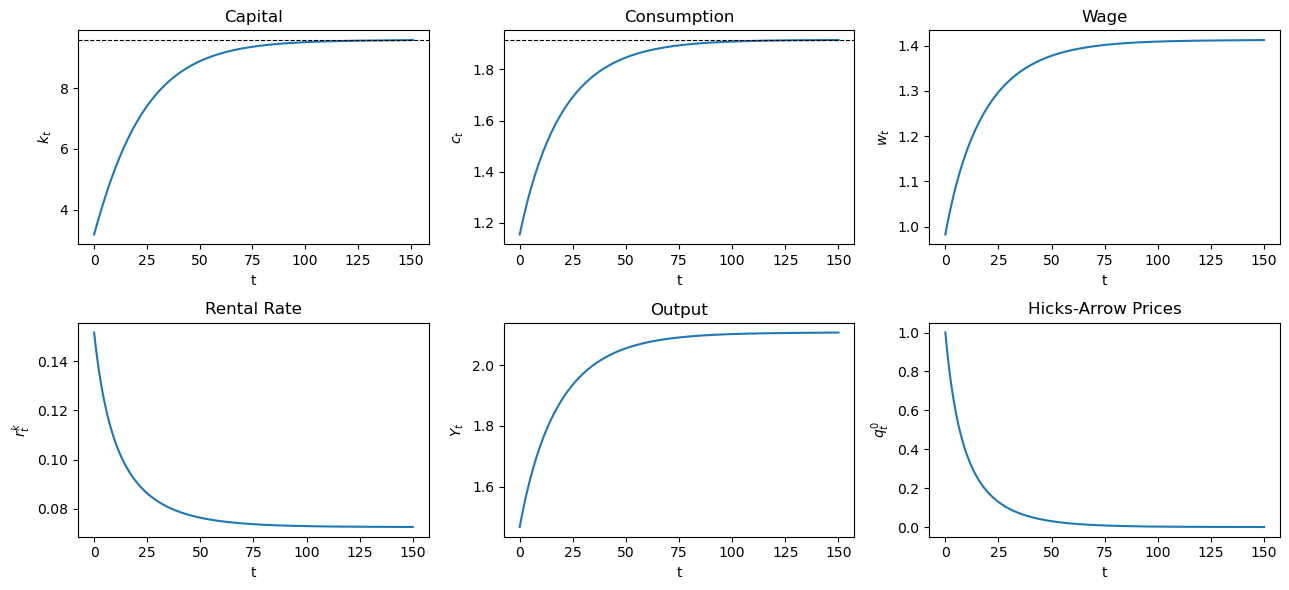

In [35]:
def plot_decentralised(s, eq):
    k_ss, c_ss = steady_state(s)
    fig, ax = plt.subplots(2, 3, figsize=(13, 6))
    series = [('Capital', eq['k'], '$k_t$', k_ss), ('Consumption', eq['c'], '$c_t$', c_ss),
              ('Wage', eq['w'], '$w_t$', None), ('Rental Rate', eq['rk'], '$r^k_t$', None),
              ('Output', eq['Y'], '$Y_t$', None), ('Hicks-Arrow Prices', eq['q'], '$q_t^0$', None)]
    for a, (title, y, ylab, ss) in zip(ax.flat, series):
        a.plot(y)
        if ss is not None:
            a.axhline(ss, color='k', ls='--', lw=0.8)
        a.set(title=title, ylabel=ylab, xlabel='t')
    plt.tight_layout()
    plt.show()


plot_decentralised(s, eq)

### Reproducing the experiments

The decentralised solver should reproduce every experiment in Part I. We rerun the horizon and curvature experiments — including the $k_{T+1} = 0$ terminal condition and high values of $\gamma$ — and report the largest gap between the decentralised solution and the planner's in each case.

In [21]:
cases = ([(f'T = {T}, k_ter = 0', get_settings(T=T, k_ter=0.0)) for T in [250, 150, 75, 50]]
         + [(f'T = 150, γ = {γ}, k_ter = 0', get_settings(T=150, gamma=γ, k_ter=0.0)) for γ in [1.1, 4, 6, 8]])

print(f'{"case":<28s}{"unknowns":>10s}{"FOC residual":>16s}{"max |diff| vs planner":>24s}')
for name, s_ in cases:
    eq_ = solve_decentralised(s_)
    d = compare_with_planner(s_, eq_, verbose=False)
    print(f'{name:<28s}{6 * s_.T + 5:>10d}{eq_["residual"]:>16.2e}{d:>24.2e}')

case                          unknowns    FOC residual   max |diff| vs planner
T = 250, k_ter = 0                1505        7.11e-15                1.78e-14
T = 150, k_ter = 0                 905        7.11e-15                1.60e-14
T = 75, k_ter = 0                  455        5.33e-15                7.11e-15
T = 50, k_ter = 0                  305        2.66e-15                5.33e-15
T = 150, γ = 1.1, k_ter = 0        905        5.33e-15                1.78e-14
T = 150, γ = 4, k_ter = 0          905        7.11e-15                1.07e-14
T = 150, γ = 6, k_ter = 0          905        7.11e-15                1.60e-14
T = 150, γ = 8, k_ter = 0          905        7.11e-15                7.11e-15


T = 250, k_ter = 0                1505        7.11e-15                2.13e-14


T = 150, k_ter = 0                 905        5.33e-15                1.24e-14


T = 75, k_ter = 0                  455        7.11e-15                8.88e-15


T = 50, k_ter = 0                  305        3.55e-15                3.55e-15


T = 150, γ = 1.1, k_ter = 0        905        5.33e-15                1.24e-14


T = 150, γ = 4, k_ter = 0          905        5.33e-15                8.88e-15


T = 150, γ = 6, k_ter = 0          905        5.33e-15                1.24e-14


T = 150, γ = 8, k_ter = 0          905        5.33e-15                2.04e-14


In every case the market economy, solved from the agents' own optimality conditions and market clearing, lands on the planner's allocation to machine precision.

## Date-0 markets

For completeness we also solve the decentralised economy under the market structure the lecture itself uses: a single market at time $0$, with the household facing one present-value budget constraint and Hicks-Arrow prices as unknowns.

Unknowns (all in logs, with $q_0^0 = 1$ as numeraire):

$$
c_0, \ldots, c_T, \quad k_1, \ldots, k_T, \quad q_1^0, \ldots, q_T^0, \quad \eta_0, \ldots, \eta_T, \quad w_0, \ldots, w_T
$$

That is $5T + 3$ unknowns. Labour and capital market clearing have been substituted in ($\tilde n_t = 1$, $\tilde k_t = k_t$), so the equations are:

| Block | Equation | Periods | Count |
|---|---|---|---|
| Household, $c_t$ FOC | $\log q_t^0 = t \log\beta + \log u'(c_t) - \log u'(c_0)$ | $1..T$ | $T$ |
| Household, $k_t$ FOC | $\log q_{t-1}^0 = \log q_t^0 + \log(1 - \delta + \eta_t)$ | $1..T$ | $T$ |
| Firm, capital | $\log \eta_t = \log f'(k_t)$ | $0..T$ | $T+1$ |
| Firm, labour | $\log w_t = \log\left(f(k_t) - k_t f'(k_t)\right)$ | $0..T$ | $T+1$ |
| Household budget / market clearing | $c_t + k_{t+1} - (1-\delta)k_t = w_t + \eta_t k_t$ | $0..T$ | $T+1$ |

which is also $5T+3$ equations. The household's $c_t$ condition has used $\lambda = u'(c_0)$, which is the normalisation $q_0^0 = 1$. The period-by-period budget equation is the household's flow constraint at firm income; given zero profits it is equivalent to goods-market clearing.

Two differences from the sequential-markets version are worth noticing. The Euler equation never appears: its role is played by the two first-order conditions for $c_t$ and $k_t$, linked through $q_t^0$. And interest rates never appear either — the Hicks-Arrow prices carry all the intertemporal information.

In [22]:
def ce_unpack(x, s):
    T = s.T
    c   = jnp.exp(x[:T + 1])
    k   = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[T + 1:2 * T + 1]), jnp.array([s.k_ter])])
    q   = jnp.concatenate([jnp.array([1.0]), jnp.exp(x[2 * T + 1:3 * T + 1])])
    eta = jnp.exp(x[3 * T + 1:4 * T + 2])
    w   = jnp.exp(x[4 * T + 2:])
    return c, k, q, eta, w


def ce_residuals(x, s):
    c, k, q, eta, w = ce_unpack(x, s)
    t = jnp.arange(1, s.T + 1)
    hh_c = jnp.log(q[1:]) - (t * jnp.log(s.beta) + jnp.log(u_prime(c[1:], s)) - jnp.log(u_prime(c[0], s)))
    hh_k = jnp.log(q[:-1]) - jnp.log(q[1:]) - jnp.log(1 - s.delta + eta[1:])
    firm_k = jnp.log(eta) - jnp.log(f_prime(k[:-1], s))
    firm_n = jnp.log(w) - jnp.log(f_prod(k[:-1], s) - k[:-1] * f_prime(k[:-1], s))
    budget = c + k[1:] - (1 - s.delta) * k[:-1] - (w + eta * k[:-1])
    return jnp.concatenate([hh_c, hh_k, firm_k, firm_n, budget])


def ce_guess(s):
    # Steady-state guess for quantities, and the prices those quantities imply
    x_planner = steady_state_guess(s)
    c, k = np.exp(x_planner[:s.T + 1]), np.exp(x_planner[s.T + 1:])
    k_full = np.concatenate([[s.k0], k])
    t = np.arange(1, s.T + 1)
    q = s.beta ** t
    eta = s.alpha * s.A * k_full ** (s.alpha - 1)
    w = (1 - s.alpha) * s.A * k_full ** s.alpha
    return np.log(np.concatenate([c, k, q, eta, w]))


def solve_ce(s, verbose=False):
    f = lambda x: ce_residuals(x, s)
    x1 = newton(f, ce_guess(s), tol=1e-6, max_iter=500, adj=0.3, verbose=verbose)
    x = newton(f, x1, tol=1e-12, max_iter=100, adj=1, verbose=verbose)
    c, k, q, eta, w = ce_unpack(x, s)
    res = float(jnp.max(jnp.abs(f(x))))
    return [np.asarray(v) for v in (c, k, q, eta, w)], res

We solve both decentralised versions for $T = 150$ and compare them with each other and with the planner.

In [23]:
s = get_settings(T=150)

(c_ce, k_ce, q_ce, eta_ce, w_ce), res_ce = solve_ce(s)
eq_seq = solve_decentralised(s)
c_pl, k_pl, _ = solve_planner(s)
q_pl, eta_pl, w_pl, _ = prices(c_pl, k_pl, s)

print(f'date-0 markets:     {5 * s.T + 3} unknowns, max |residual| = {res_ce:.2e}')
print(f'sequential markets: {6 * s.T + 5} unknowns, max |residual| = {eq_seq["residual"]:.2e}\n')

print(f'{"":<6s}{"date-0 vs planner":>20s}{"sequential vs planner":>24s}')
for name, a, b, p in [('c', c_ce, eq_seq['c'], c_pl), ('k', k_ce, eq_seq['k'], k_pl),
                      ('q', q_ce, eq_seq['q'], q_pl), ('eta', eta_ce, eq_seq['rk'], eta_pl),
                      ('w', w_ce, eq_seq['w'], w_pl)]:
    print(f'{name:<6s}{np.max(np.abs(a - p)):>20.2e}{np.max(np.abs(b - p)):>24.2e}')

date-0 markets:     753 unknowns, max |residual| = 5.33e-15
sequential markets: 905 unknowns, max |residual| = 7.11e-15

         date-0 vs planner   sequential vs planner
c                 2.44e-15                1.33e-15
k                 1.42e-14                1.42e-14
q                 3.33e-16                3.89e-16
eta               8.33e-17                9.71e-17
w                 8.88e-16                8.88e-16


Three different computations — the planning problem, a date-0 market economy and a sequential market economy — deliver the same allocation and the same prices.

This is a numerical illustration of the first and second welfare theorems for this economy: the competitive allocation is the planner's optimum, and the planner's optimum can be supported by competitive prices. It also shows that, in this complete-markets setting without frictions, the choice between a single date-0 market and a sequence of spot markets for factors is immaterial: no-arbitrage pins down Hicks-Arrow prices from sequential interest rates, and vice versa.